<a href="https://colab.research.google.com/github/dishagupta03/Parkinson-s-Disease-Detection/blob/main/Parkinson's_Disease_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset loaded successfully!
Dataset shape: (195, 24)

First five rows:
             name  MDVP:Fo(Hz)  MDVP:Fhi(Hz)  MDVP:Flo(Hz)  MDVP:Jitter(%)  \
0  phon_R01_S01_1      119.992       157.302        74.997         0.00784   
1  phon_R01_S01_2      122.400       148.650       113.819         0.00968   
2  phon_R01_S01_3      116.682       131.111       111.555         0.01050   
3  phon_R01_S01_4      116.676       137.871       111.366         0.00997   
4  phon_R01_S01_5      116.014       141.781       110.655         0.01284   

   MDVP:Jitter(Abs)  MDVP:RAP  MDVP:PPQ  Jitter:DDP  MDVP:Shimmer  ...  \
0           0.00007   0.00370   0.00554     0.01109       0.04374  ...   
1           0.00008   0.00465   0.00696     0.01394       0.06134  ...   
2           0.00009   0.00544   0.00781     0.01633       0.05233  ...   
3           0.00009   0.00502   0.00698     0.01505       0.05492  ...   
4           0.00011   0.00655   0.00908     0.01966       0.06425  ...   

   Shimmer:DDA

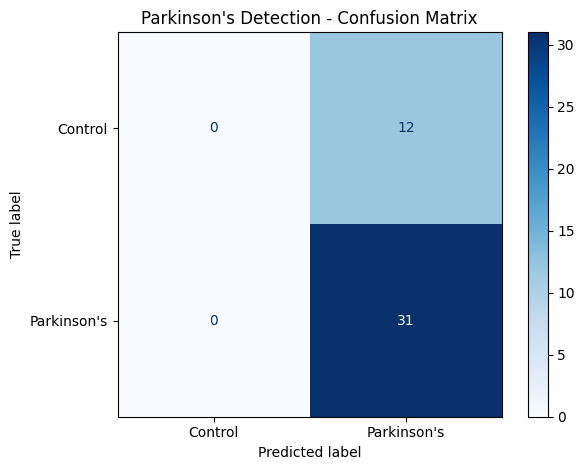


Top 10 Important Features:
PPE                 0.152820
spread1             0.133785
spread2             0.103384
MDVP:Fo(Hz)         0.082465
RPDE                0.078614
MDVP:Fhi(Hz)        0.054076
MDVP:APQ            0.050692
MDVP:Jitter(%)      0.049808
MDVP:Jitter(Abs)    0.037656
MDVP:Flo(Hz)        0.034249
dtype: float64


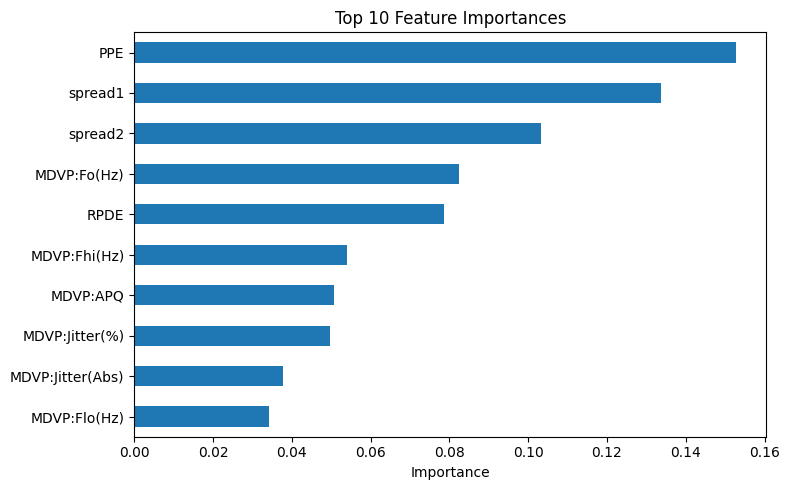


Project execution completed successfully!


In [1]:

# Parkinson's Disease Detection using Machine Learning
# Dataset: UCI Parkinson's Voice Dataset
# Model: Random Forest Classifier

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.request import urlopen
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Load dataset automatically
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/parkinsons/parkinsons.data"
df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# 2. Prepare features and target
target_col = "status"

if target_col not in df.columns:
    raise ValueError("Target column 'status' was not found.")

# Keep patient/record identifiers out of model features
names = df["name"].astype(str)
groups = names.str.extract(r"(S\d+)", expand=False)

if groups.isna().any():
    raise ValueError("Could not identify all participant IDs.")

X = df.drop(columns=["name", target_col])
X = X.select_dtypes(include=[np.number])
y = df[target_col].astype(int)

print("\nNumber of features:", X.shape[1])
print("\nClass distribution:")
print(y.value_counts().sort_index())

# 3. Split by participant to reduce data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 4. Build and train the model
model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42
    )
)

model.fit(X_train, y_train)

# 5. Make predictions
y_pred = model.predict(X_test)

# 6. Display actual evaluation results
accuracy = accuracy_score(y_test, y_pred)

print("\n========== MODEL RESULTS ==========")
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Control", "Parkinson's"],
    zero_division=0
))

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Control", "Parkinson's"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Parkinson's Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

# 8. Feature importance
rf = model.named_steps["randomforestclassifier"]

importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nTop 10 Important Features:")
print(importance.head(10))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nProject execution completed successfully!")
